In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("C:/Users/Kate/Downloads/titanic/train.csv")
df_raw = df.copy()

print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")
df.head()

Rows: 891, columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.dtypes.to_frame('dtype')

,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [4]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
PassengerId,891.0,446.000,257.354,1.00,223.500,446.000,668.5,891.000,0.000,-1.200
Survived,891.0,0.384,0.487,0.00,0.000,0.000,1.0,1.000,0.479,-1.775
Pclass,891.0,2.309,0.836,1.00,2.000,3.000,3.0,3.000,-0.631,-1.280
Age,714.0,29.699,14.526,0.42,20.125,28.000,38.0,80.000,0.389,0.178
SibSp,891.0,0.523,1.103,0.00,0.000,0.000,1.0,8.000,3.695,17.880
Parch,891.0,0.382,0.806,0.00,0.000,0.000,0.0,6.000,2.749,9.778
Fare,891.0,32.204,49.693,0.00,7.910,14.454,31.0,512.329,4.787,33.398


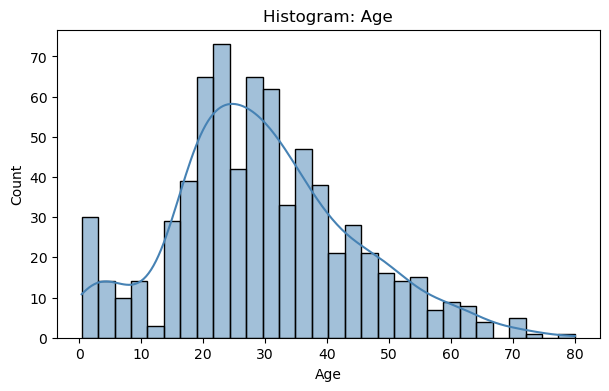

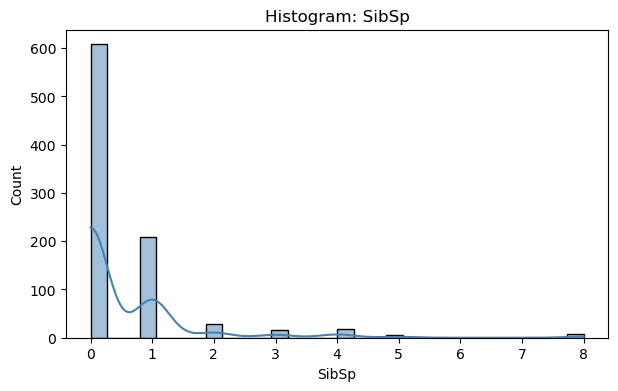

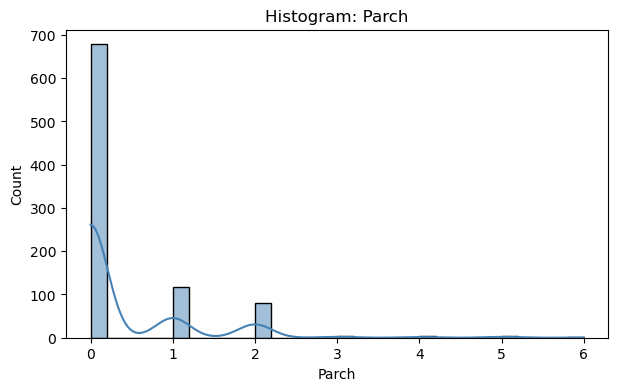

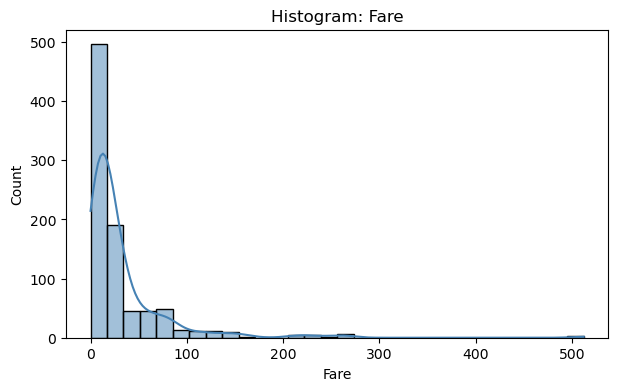

In [7]:
plot_cols = ["Age", "SibSp", "Parch", "Fare"]

for c in plot_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[c].dropna(), bins=30, kde=True, color="steelblue")
    plt.title(f"Histogram: {c}")
    plt.show()

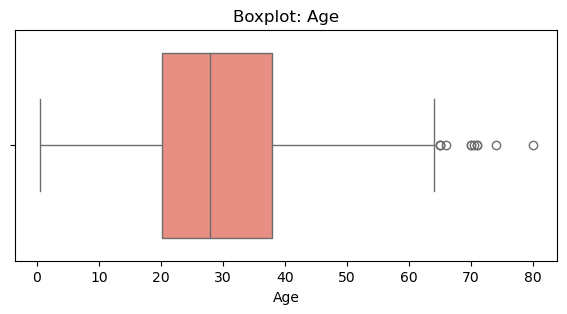

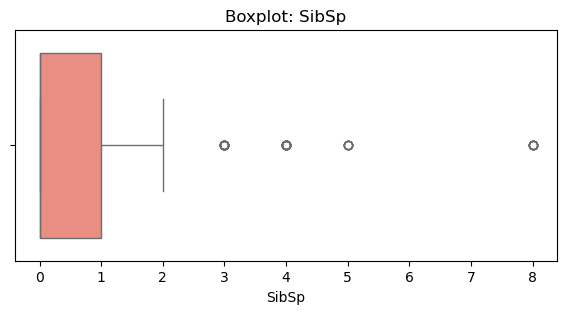

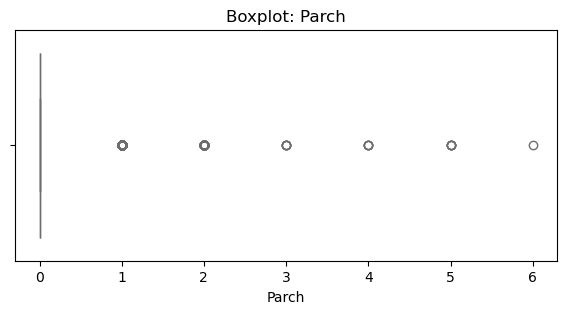

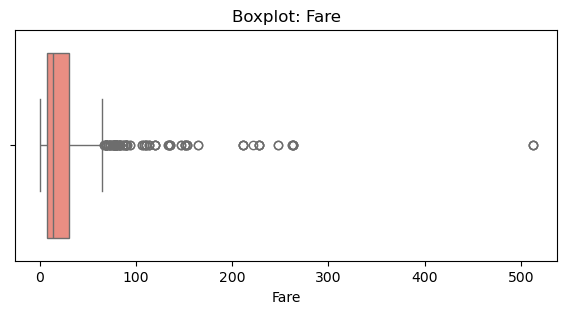

In [8]:
for c in plot_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[c], color="salmon")
    plt.title(f"Boxplot: {c}")
    plt.show()

In [9]:
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

pd.Series({c: count_outliers(df[c]) for c in plot_cols}, name="outliers (1.5*IQR)").to_frame()

,outliers (1.5*IQR)
Age,11
SibSp,46
Parch,213
Fare,116


In [10]:
missing = pd.DataFrame({"count": df.isna().sum(), "percent": (df.isna().mean() * 100).round(2)})
missing[missing["count"] > 0].sort_values("count", ascending=False)

,count,percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


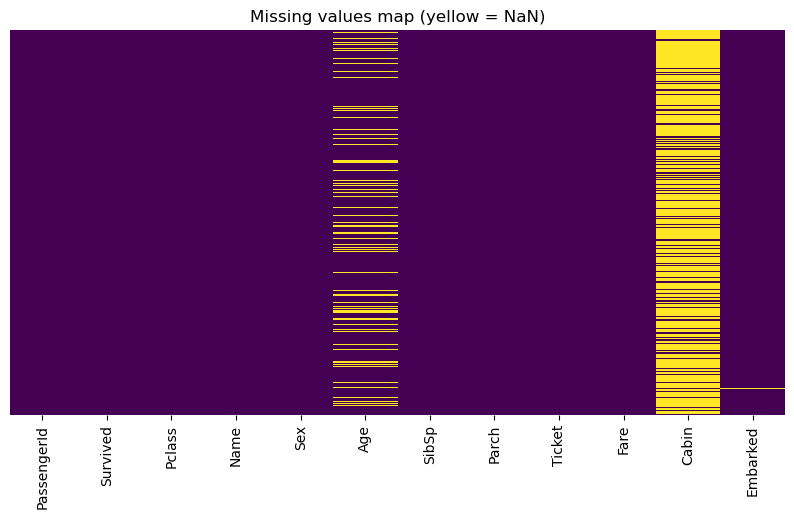

In [11]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values map (yellow = NaN)")
plt.show()

In [12]:
df["HasCabin"] = df["Cabin"].notna().astype(int)
df["Deck"] = df["Cabin"].str[0].fillna("U")  # U = Unknown

In [13]:
fill_values = {}
for c in df_raw.columns[df_raw.isna().any()]:
    fill_values[c] = df[c].median() if c in num_cols else df[c].mode()[0]
    df[c] = df[c].fillna(fill_values[c])

print("Fill values:", fill_values)
print("Remaining NaN:", int(df.isna().sum().sum()))

Fill values: {'Age': 28.0, 'Cabin': 'B96 B98', 'Embarked': 'S'}
Remaining NaN: 0


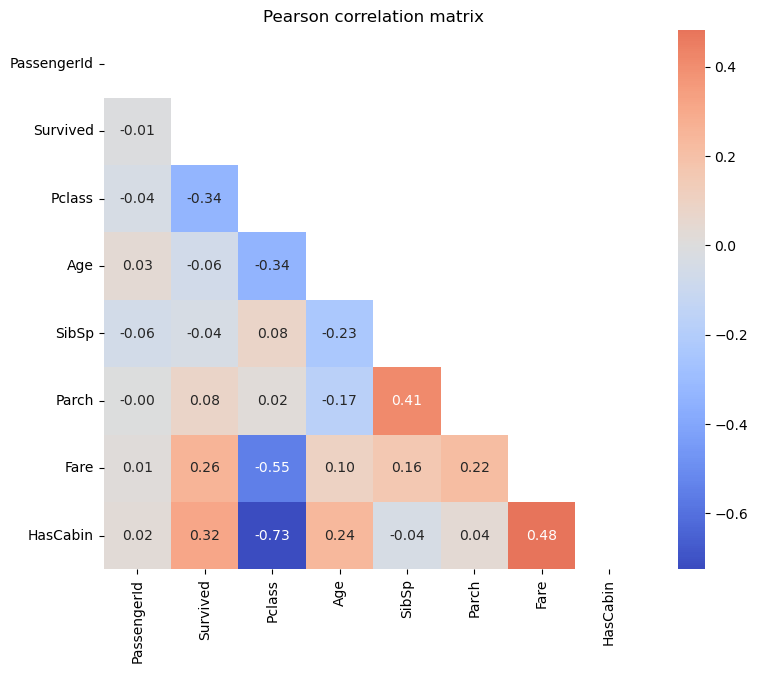

In [14]:
corr = df[num_cols + ["HasCabin"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Pearson correlation matrix")
plt.show()

In [15]:
pairs = (
    corr.where(~mask & ~np.eye(len(corr), dtype=bool))
    .stack()
    .rename("corr")
    .rename_axis(["feature_1", "feature_2"])
    .reset_index()
)
pairs.reindex(pairs["corr"].abs().sort_values(ascending=False).index).head(5).round(3).reset_index(drop=True)

,feature_1,feature_2,corr
0,HasCabin,Pclass,-0.726
1,Fare,Pclass,-0.549
2,HasCabin,Fare,0.482
3,Parch,SibSp,0.415
4,Age,Pclass,-0.340


title -> name

familySize/isAlone -> sibSp + Parch + 1 and "travels alone" flag

hasCabin/Deck -> known cabin/ deck letter

ticketGroupSize/farePerPerson -> passengers sharing a ticket and fare divided between them

agedGroup - binned age

In [16]:
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
rare_titles = ["Dr", "Rev", "Col", "Major", "Capt", "Don", "Sir", "Jonkheer", "the Countess", "Lady", "Dona"]
df["Title"] = df["Title"].replace(rare_titles, "Rare")

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df["TicketGroupSize"] = df.groupby("Ticket")["PassengerId"].transform("count")
df["FarePerPerson"] = df["Fare"] / df["TicketGroupSize"]

df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 12, 18, 35, 60, 120],
    labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"],
).astype(str)

new_features = ["HasCabin", "Deck", "Title", "FamilySize", "IsAlone", "TicketGroupSize", "FarePerPerson", "AgeGroup"]
df[new_features].head()

,HasCabin,Deck,Title,FamilySize,IsAlone,TicketGroupSize,FarePerPerson,AgeGroup
0,0,U,Mr,2,0,1,7.2500,YoungAdult
1,1,C,Mrs,2,0,1,71.2833,Adult
2,0,U,Miss,1,1,1,7.9250,YoungAdult
3,1,C,Mrs,2,0,2,26.5500,YoungAdult
4,0,U,Mr,1,1,1,8.0500,YoungAdult


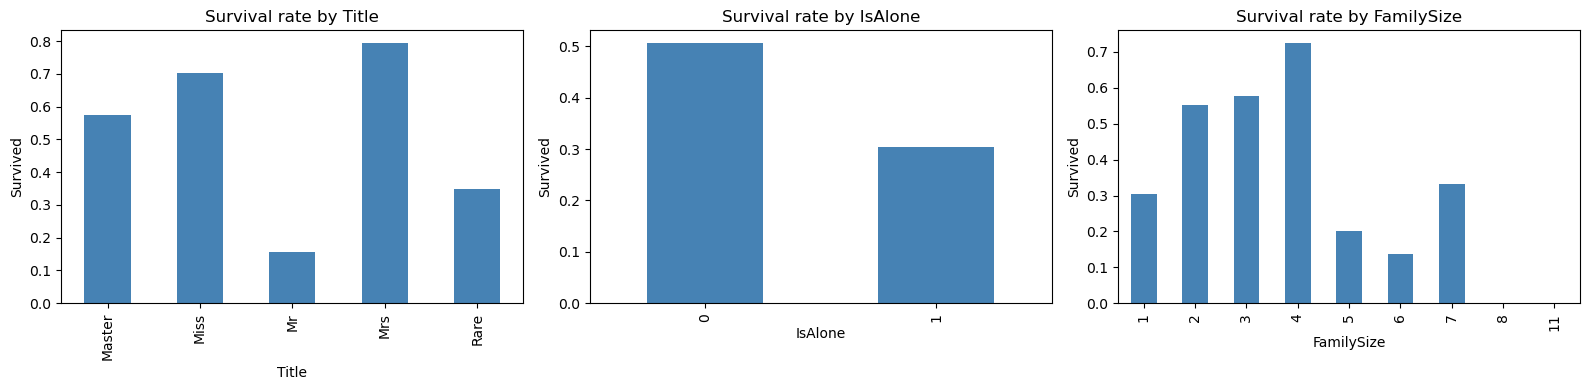

In [17]:
survival = {name: df.groupby(name)["Survived"].mean() for name in ["Title", "IsAlone", "FamilySize"]}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, rate) in zip(axes, survival.items()):
    rate.plot.bar(ax=ax, color="steelblue")
    ax.set_title(f"Survival rate by {name}")
    ax.set_ylabel("Survived")
plt.tight_layout()
plt.show()

In [ ]:
df_before = df.copy()

df_model = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])
df_model["Pclass"] = df_model["Pclass"].astype(str)

ohe_cols = ["Sex", "Embarked", "Pclass", "Title", "Deck", "AgeGroup"]
df_enc = pd.get_dummies(df_model, columns=ohe_cols, dtype=int)
print(f"Columns after OHE: {df_enc.shape[1]} (before: {df_model.shape[1]})")

Columns after OHE: 37 (before: 16)


In [19]:
scale_cols = ["Age", "SibSp", "Parch", "Fare", "FamilySize", "TicketGroupSize", "FarePerPerson"]

df_final = df_enc.copy()
df_final[scale_cols] = StandardScaler().fit_transform(df_enc[scale_cols])

print("Final shape:", df_final.shape)
df_final[scale_cols].agg(["mean", "std"]).round(4)

Final shape: (891, 37)


,Age,SibSp,Parch,Fare,FamilySize,TicketGroupSize,FarePerPerson
mean,0.0000,0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000
std,1.0006,1.0006,1.0006,1.0006,1.0006,1.0006,1.0006


In [20]:
df_final.head()

,Survived,Age,SibSp,Parch,Fare,HasCabin,FamilySize,IsAlone,TicketGroupSize,FarePerPerson,...,Deck_E,Deck_F,Deck_G,Deck_T,Deck_U,AgeGroup_Adult,AgeGroup_Child,AgeGroup_Senior,AgeGroup_Teen,AgeGroup_YoungAdult
0,0,-0.565736,0.432793,-0.473674,-0.502445,0,0.059160,0,-0.579162,-0.496976,...,0,0,0,0,1,0,0,0,0,1
1,1,0.663861,0.432793,-0.473674,0.786845,1,0.059160,0,-0.579162,2.522573,...,0,0,0,0,0,1,0,0,0,0
2,1,-0.258337,-0.474545,-0.473674,-0.488854,0,-0.560975,1,-0.579162,-0.465145,...,0,0,0,0,1,0,0,0,0,1
3,1,0.433312,0.432793,-0.473674,0.420730,1,0.059160,0,0.155928,0.413134,...,0,0,0,0,0,0,0,0,0,1
4,0,0.433312,-0.474545,-0.473674,-0.486337,0,-0.560975,1,-0.579162,-0.459251,...,0,0,0,0,1,0,0,0,0,1


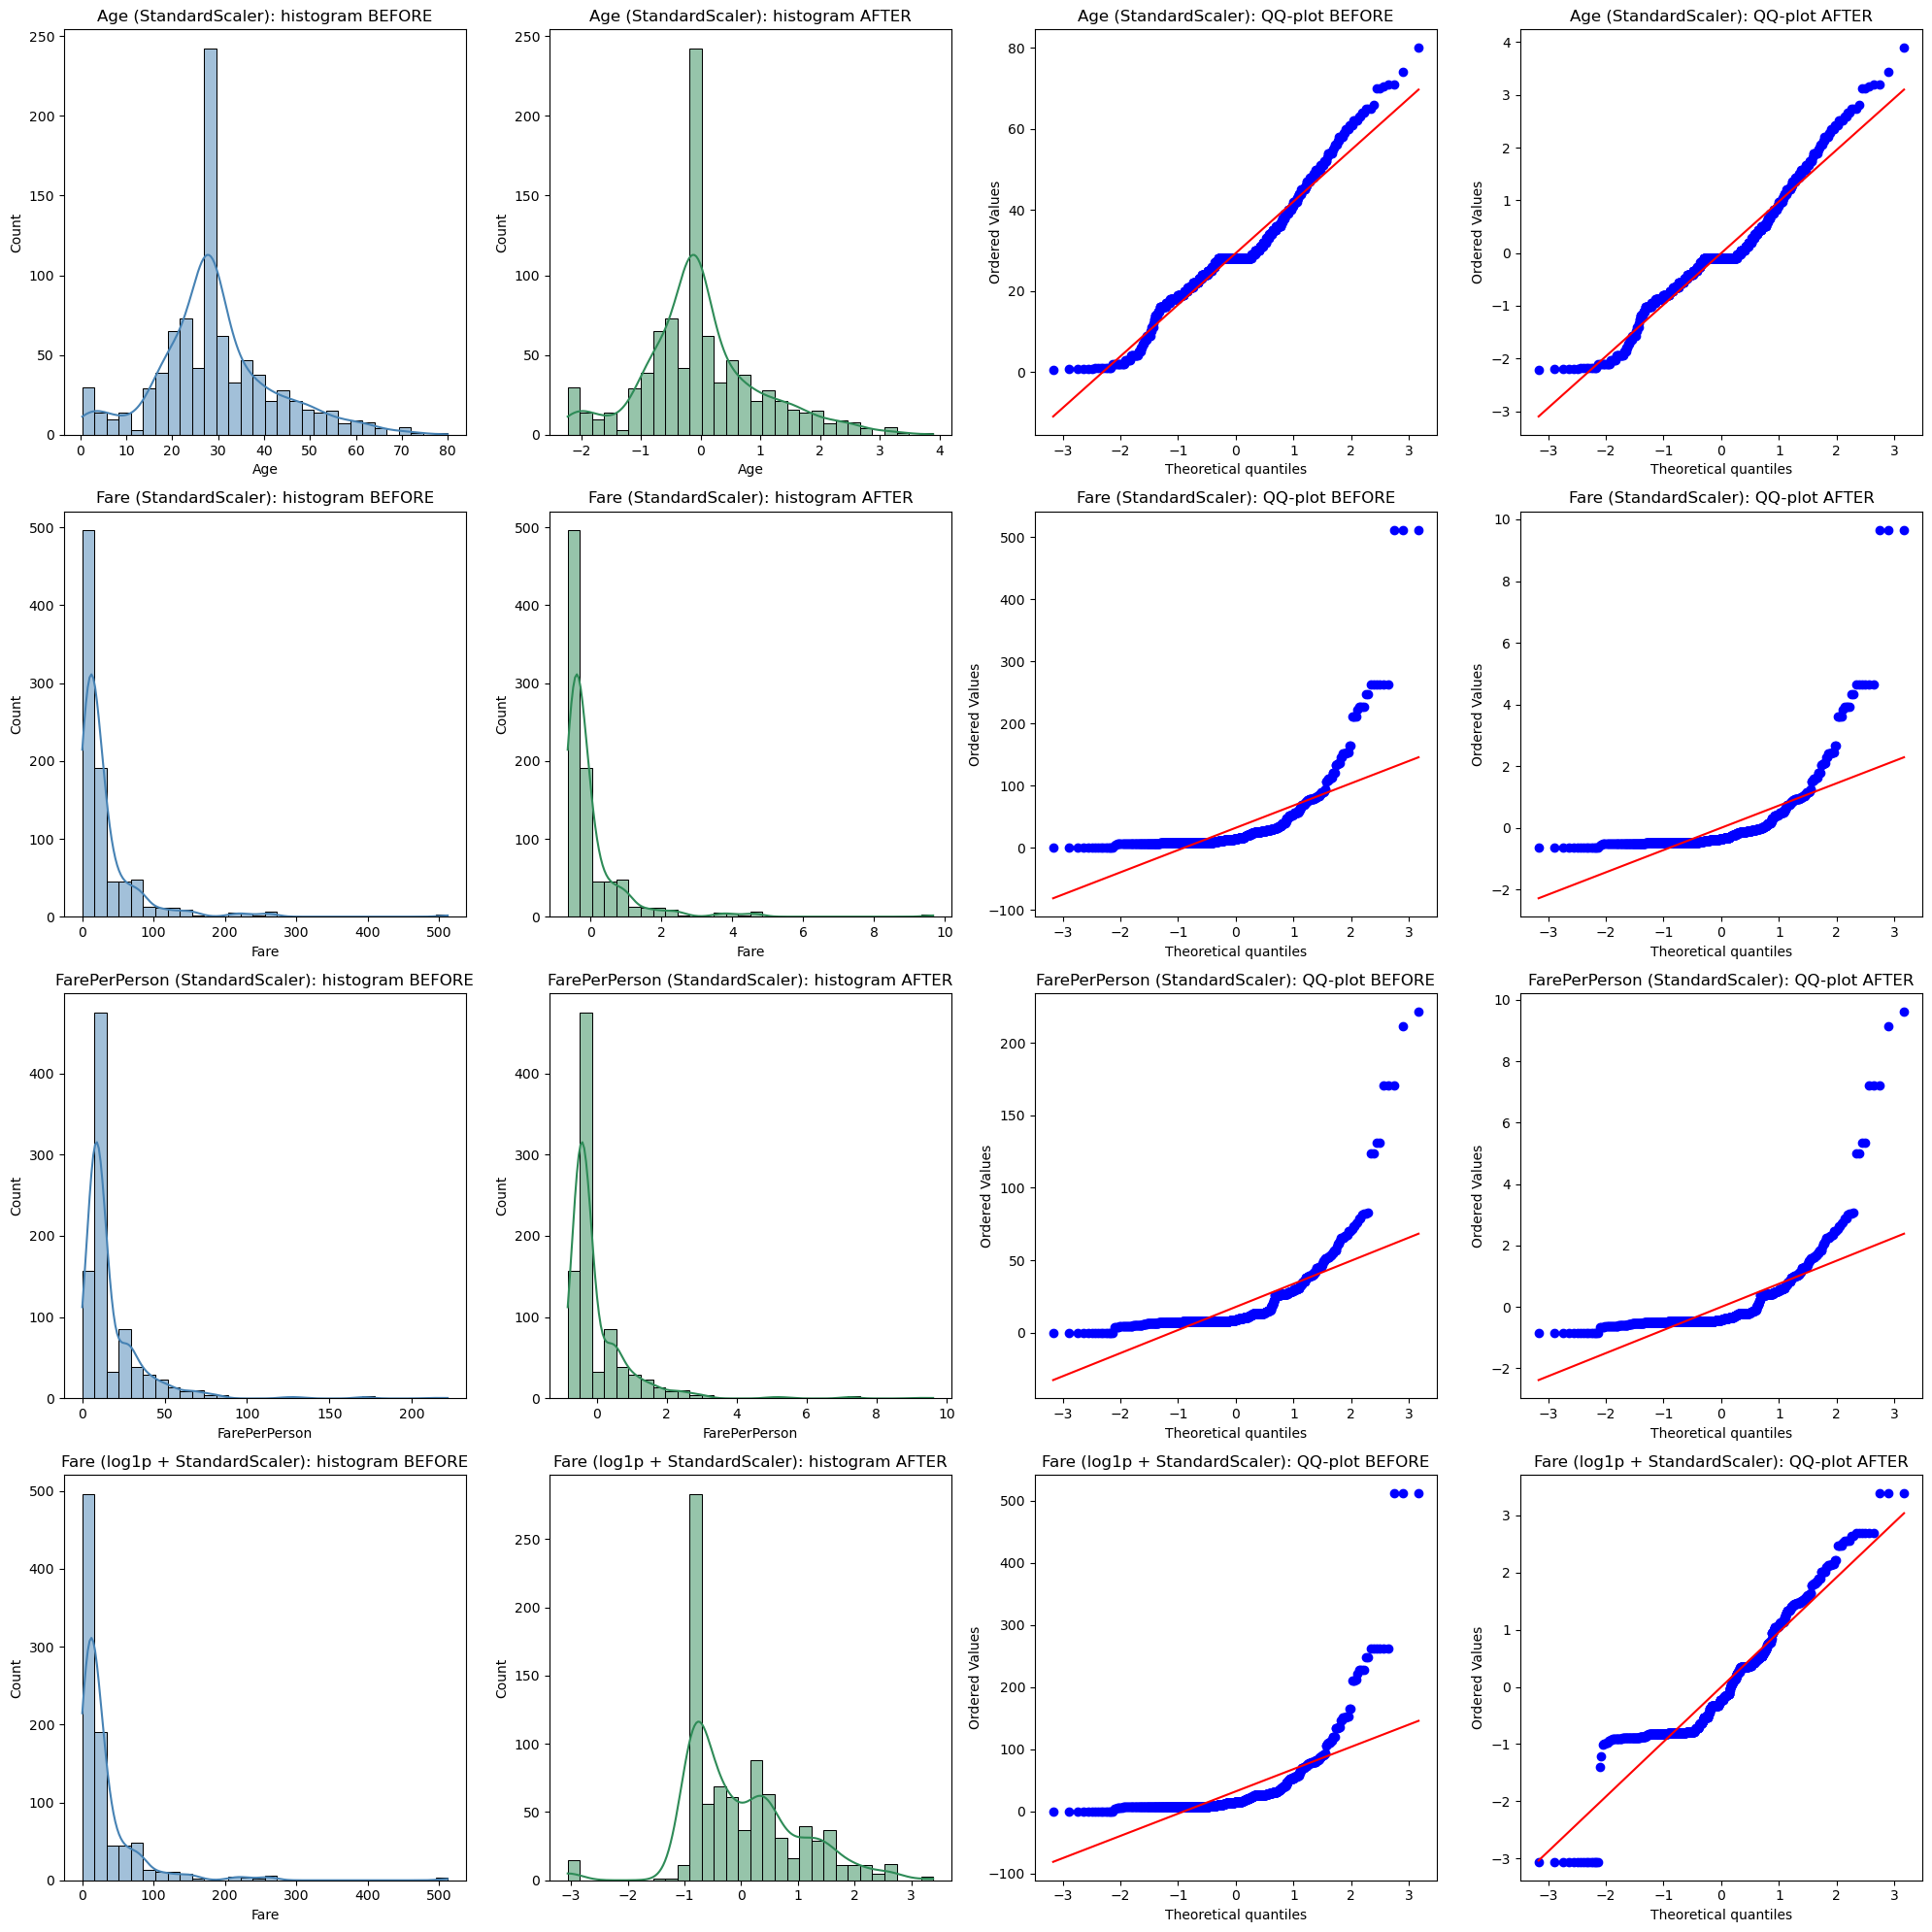

In [21]:
def compare_row(axes_row, before, after, name):
    sns.histplot(before, bins=30, kde=True, ax=axes_row[0], color="steelblue")
    axes_row[0].set_title(f"{name}: histogram BEFORE")
    sns.histplot(after, bins=30, kde=True, ax=axes_row[1], color="seagreen")
    axes_row[1].set_title(f"{name}: histogram AFTER")
    stats.probplot(before, dist="norm", plot=axes_row[2])
    axes_row[2].set_title(f"{name}: QQ-plot BEFORE")
    stats.probplot(after, dist="norm", plot=axes_row[3])
    axes_row[3].set_title(f"{name}: QQ-plot AFTER")


compare_cols = ["Age", "Fare", "FarePerPerson"]
fare_log_scaled = StandardScaler().fit_transform(np.log1p(df_before[["Fare"]])).ravel()

fig, axes = plt.subplots(len(compare_cols) + 1, 4, figsize=(20, 5 * (len(compare_cols) + 1)))
for ax_row, c in zip(axes, compare_cols):
    compare_row(ax_row, df_before[c], df_final[c], f"{c} (StandardScaler)")
compare_row(axes[-1], df_before["Fare"], fare_log_scaled, "Fare (log1p + StandardScaler)")
plt.tight_layout()
plt.show()

In [22]:
summary = pd.DataFrame(
    {
        "skew before": {c: stats.skew(df_before[c]) for c in compare_cols} | {"Fare (log1p+SS)": stats.skew(df_before["Fare"])},
        "skew after": {c: stats.skew(df_final[c]) for c in compare_cols} | {"Fare (log1p+SS)": stats.skew(fare_log_scaled)},
    }
)
summary.round(3)

,skew before,skew after
Age,0.509,0.509
Fare,4.779,4.779
FarePerPerson,4.373,4.373
Fare (log1p+SS),4.779,0.394
